In [ ]:
import os

# Select the backend before the first PyRITE import; restart to change it.
os.environ.setdefault("PYRITE_MC_BACKEND", "cpu")
import marimo as mo  # noqa: F401
import matplotlib.pyplot as plt
import numpy as np

import pyrite

_ = pyrite.fetch_tables()  # Reuse the installed tables without network access.
tables_ready = True

# Sampling, convergence and performance

[![Open in Molab](https://marimo.io/molab-shield.svg)](https://molab.marimo.io/github/Quantum-Light-Matter-Cooperative-QLMC/pyrite/blob/main/docs/notebooks/07-sampling-convergence-performance.py)

How many electron histories does a PXR/CBS yield need? Repeat each
history budget with **independent seeds**, measure the spread, and compare
it with the $1/\sqrt{N}$ law and with an adaptive stopping rule. All runs
use a 30 keV beam, 100 nm HOPG, 135° observation and no bremsstrahlung.

The observable is the source yield integrated over **600–2,000 eV**, in
photons / (incident electron · sr). Sampled histories are numerical
estimators, not physical bunch charge.

In [ ]:
assert tables_ready  # Wait for reference tables before executing transport.
from time import perf_counter

from pyrite import simulate
from pyrite.beams import Beam, PointBunch, PointSpot
from pyrite.config import AdaptiveSampling, CxrReflections, FixedSampling, Numerics, Physics
from pyrite.detectors import Detector
from pyrite.geometry import Footprint, Slab
from pyrite.units import ureg

beam = Beam(kinetic_energy=30 * ureg.keV, transverse=PointSpot(), longitudinal=PointBunch())
target = Slab(
    "hopg",
    thickness=100 * ureg.nm,
    tilt=30 * ureg.degree,
    footprint=Footprint(width=5 * ureg.mm, height=5 * ureg.mm),
)
detector = Detector(observation_angle=135 * ureg.degree)
physics = Physics(brem_source="none")
band_eV = (600.0, 2_000.0)
budgets = (256, 512, 1_024, 2_048, 4_096, 8_192)
replicates = 6


def run(sampling, seed):
    """Simulate one case; fixed and adaptive runs share the same transport core."""
    numerics = Numerics(
        sampling=sampling,
        cxr_reflections=CxrReflections(n_families=2),
        transport_core="per-electron",
        seed=seed,
    )
    start = perf_counter()
    result = simulate(beam, target, detector, physics=physics, numerics=numerics)
    return result, perf_counter() - start


def band_yield(result):
    """Integrate the CXR density over the band, with interpolated band edges."""
    spectrum = result.cxr.incoherent
    grid, lo, hi = spectrum.photon_energy_eV, *band_eV
    nodes = np.r_[lo, grid[(grid > lo) & (grid < hi)], hi]
    return float(np.trapezoid(np.interp(nodes, grid, spectrum.density), nodes))

In [ ]:
assert tables_ready  # Wait for reference tables before executing transport.
_ = run(FixedSampling(cxr_electrons=16, brem_electrons=16), seed=1)  # untimed warmup
yields = np.zeros((len(budgets), replicates))
seconds = np.zeros_like(yields)
for _i, _n in enumerate(budgets):
    for _k in range(replicates):
        # A distinct seed per (budget, replicate) makes every run independent.
        _result, seconds[_i, _k] = run(
            FixedSampling(cxr_electrons=_n, brem_electrons=_n), seed=1_000 * _i + _k + 1
        )
        yields[_i, _k] = band_yield(_result)
assert np.isfinite(yields).all() and (yields > 0).all()
mean = yields.mean(axis=1)
rse = yields.std(axis=1, ddof=1) / mean  # empirical relative standard error of one run
# Fit RSE = c / sqrt(N) in log space.
rse_scale = float(np.exp(np.mean(np.log(rse * np.sqrt(budgets)))))

## Adaptive stopping

`AdaptiveSampling` transports electrons in blocks and stops once its own
estimate of the **per-run** relative standard error (RSE) of the CXR band
reaches `target_rse`, subject to effective-sample-size, maximum-share and
stability guards. It needs no replicate runs: the estimate comes from the
spread of per-electron contributions within one run.

In [ ]:
assert tables_ready
policy = AdaptiveSampling(
    target_rse=5e-4,
    max_electrons=32_768,
    block_electrons=256,  # stopping is checked after each block
    observables=("cxr",),
    band_eV=band_eV,
)
adaptive_result, adaptive_seconds = run(policy, seed=99)
_stop = adaptive_result.provenance["adaptive_sampling"]
adaptive = {
    "histories": int(_stop["realized_electrons"]),
    "stop_reason": _stop["stop_reason"],
    "statistics_limited": _stop["statistics_limited"],
    "rse": float(_stop["statistics"]["cxr"]["relative_se"]),
    "guards_passed": _stop["statistics"]["cxr"]["passes"],
    "yield": band_yield(adaptive_result),
}

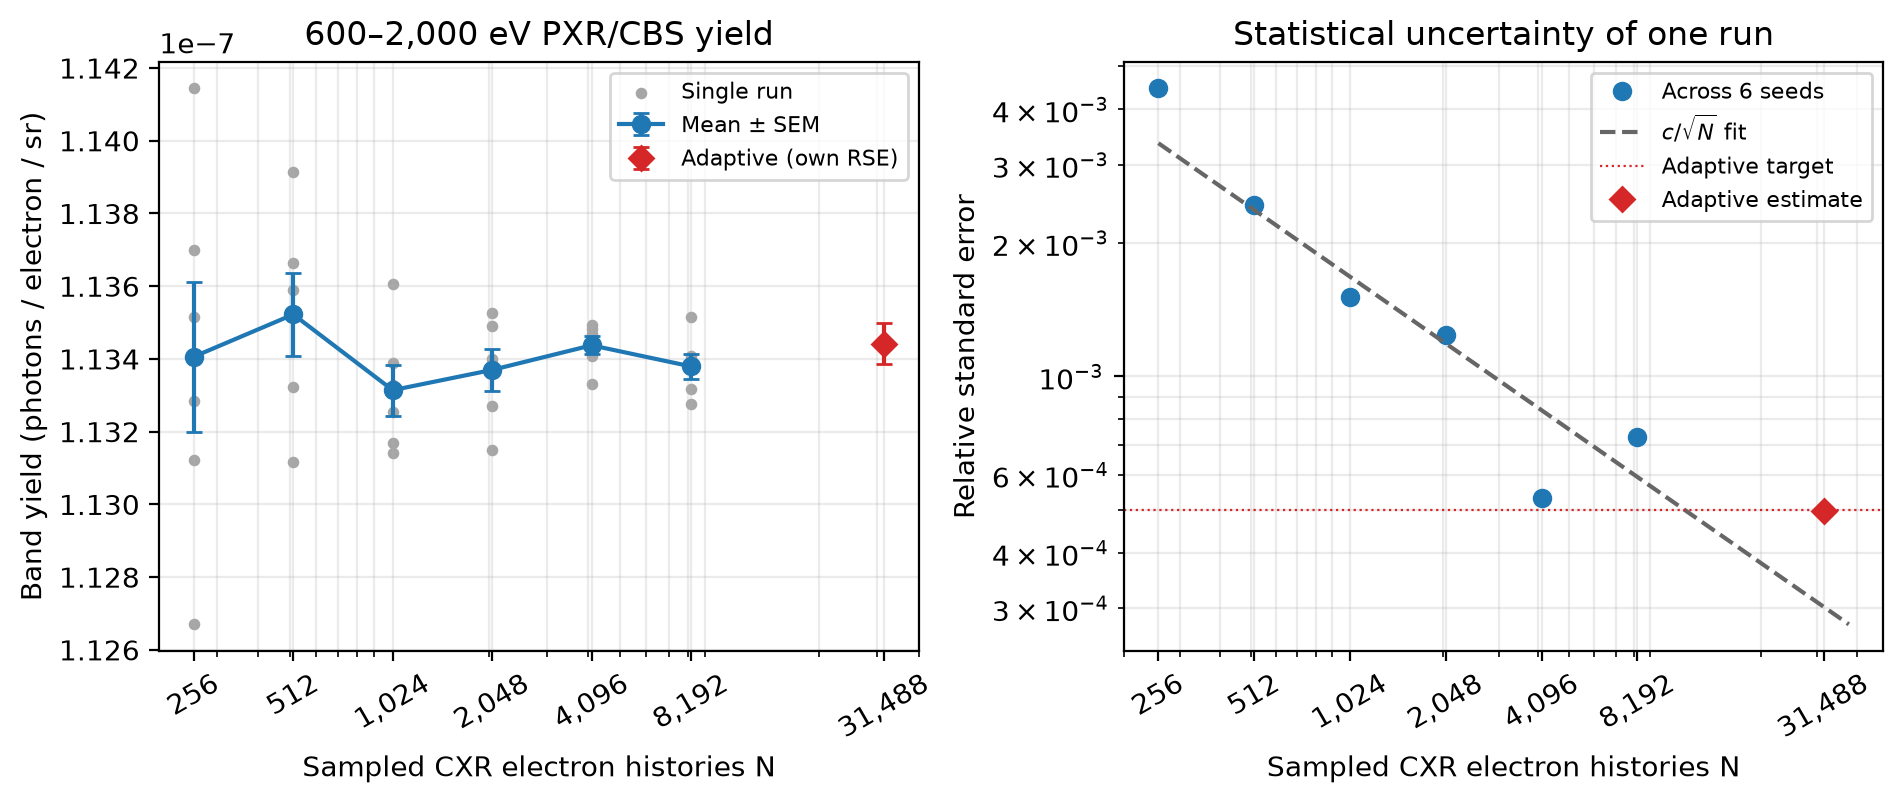

In [ ]:
from matplotlib.ticker import NullFormatter

_n = np.array(budgets, dtype=float)
_n_fine = np.geomspace(_n[0], 1.2 * max(_n[-1], adaptive["histories"]), 50)

fig_convergence, (_yield_ax, _rse_ax) = plt.subplots(1, 2, figsize=(9.4, 3.9), layout="constrained")
for _k in range(replicates):
    _yield_ax.scatter(
        _n, yields[:, _k], s=10, color="0.65", label="Single run" if _k == 0 else None
    )
_yield_ax.errorbar(
    _n, mean, yerr=mean * rse / np.sqrt(replicates), fmt="o-", capsize=3, label="Mean ± SEM"
)
_yield_ax.errorbar(
    adaptive["histories"],
    adaptive["yield"],
    yerr=adaptive["yield"] * adaptive["rse"],
    fmt="D",
    color="C3",
    capsize=3,
    label="Adaptive (own RSE)",
)
_yield_ax.set(
    xscale="log",
    xlabel="Sampled CXR electron histories N",
    ylabel="Band yield (photons / electron / sr)",
    title="600–2,000 eV PXR/CBS yield",
)
_yield_ax.legend(fontsize=8)

_rse_ax.loglog(_n, rse, "o", label=f"Across {replicates} seeds")
_rse_ax.loglog(_n_fine, rse_scale / np.sqrt(_n_fine), "--", color="0.4", label=r"$c/\sqrt{N}$ fit")
_rse_ax.axhline(policy.target_rse, color="C3", lw=0.8, ls=":", label="Adaptive target")
_rse_ax.loglog(adaptive["histories"], adaptive["rse"], "D", color="C3", label="Adaptive estimate")
_rse_ax.set(
    xlabel="Sampled CXR electron histories N",
    ylabel="Relative standard error",
    title="Statistical uncertainty of one run",
)
_rse_ax.legend(fontsize=8)
for _ax in (_yield_ax, _rse_ax):
    _ticks = (*budgets, adaptive["histories"])
    _ax.set_xticks(_ticks, labels=[f"{_b:,}" for _b in _ticks], rotation=30)
    _ax.xaxis.set_minor_formatter(NullFormatter())
    _ax.grid(alpha=0.25, which="both")
fig_convergence  # noqa: B018 - captured by marimo

In [ ]:
_per_history_ms = 1_000 * np.median(seconds[-2:] / np.array(budgets[-2:])[:, None])
_extrapolated = rse_scale / np.sqrt(adaptive["histories"])
mo.md(
    f"Largest fixed budgets: **{_per_history_ms:.2f} ms per history** (median, this CPU). "
    f"The adaptive run stopped after **{adaptive['histories']:,} histories** "
    f"(`{adaptive['stop_reason']}`, statistics-limited: {adaptive['statistics_limited']}, "
    f"guards passed: {all(adaptive['guards_passed'].values())}) in **{adaptive_seconds:.1f} s**. "
    f"Its internal RSE is "
    f"**{adaptive['rse'] / _extrapolated:.1f}×** the replicate fit extrapolated to that budget."
)

Largest fixed budgets: **0.37 ms per history** (median, this CPU). The adaptive run stopped after **31,488 histories** (`converged`, statistics-limited: False, guards passed: True) in **28.4 s**. Its internal RSE is **1.6×** the replicate fit extrapolated to that budget.

## Interpretation

Independent runs scatter about a common mean, and their spread falls as
$1/\sqrt{N}$: halving the uncertainty costs four times the histories, and
wall time grows linearly with $N$. The adaptive run estimates its *own*
RSE from the spread of per-electron contributions, without replicates; a
ratio near one means a single run can report its own error bar. Six seeds
estimate an RSE only to roughly ±30 %, and extrapolating the fit adds more
uncertainty, so judge the trend rather than individual points.

A band integral averages many lines, so this thin-target yield is already
sub-percent precise at a few hundred histories. Individual spectral bins,
weak lines and angular maps converge far more slowly; set the target on the
observable you will actually report.

Before calling an adaptive run converged, check `stop_reason`,
`statistics_limited` and every entry in `guards_passed`. Sampling error is
not the only error: changing reflection families or the photon grid tests
discretization, which more histories cannot reduce.

Timings include compilation caches and depend on hardware; they are not
portable benchmarks. For GPU runs, set `PYRITE_MC_BACKEND="cuda"` before the
first import and use `transport_core="cuda"` consistently. See the
[sampling reference](https://pyrite.readthedocs.io/en/latest/reference/python-api/config.html),
[statistical methods](https://pyrite.readthedocs.io/en/latest/computation/statistical-methods.html)
and [performance guidance](https://pyrite.readthedocs.io/en/latest/computation/index.html).

## Continue learning

Next: [Parameter sweeps](08-parameter-sweeps.ipynb).
See [precision and tolerances](../../computation/precision-and-tolerances.md)
for stopping controls and the [configuration API](../../reference/python-api/config.md)
for their Python interfaces. [Statistical methods](../../computation/statistical-methods.md)
explain uncertainty; [adaptive-stopping evidence](../../validation/beam-transport/adaptive-sample-size-stopping.md)
records the estimator's assumptions and checks.

{download}`Download canonical Marimo notebook <../07-sampling-convergence-performance.py>`